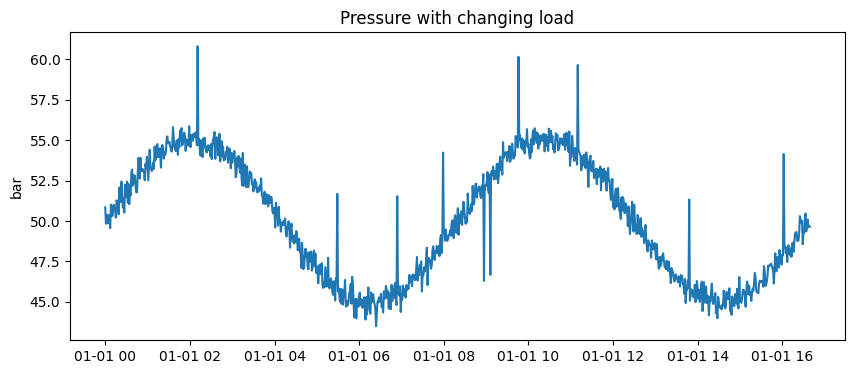

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(7)
n = 1000
time = pd.date_range("2026-01-01", periods=n, freq="min")

# ضغط يتغير ببطء مع الوقت (يمثل تغير الحمل)
trend = 50 + 5 * np.sin(np.linspace(0, 4 * np.pi, n))
pressure = trend + np.random.normal(0, 0.5, n)

# نضيف 10 شواذ
idx = np.random.choice(n, 10, replace=False)
pressure[idx] += np.random.choice([-6, 6], 10)

df = pd.DataFrame({"time": time, "pressure": pressure})

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["pressure"])
plt.title("Pressure with changing load")
plt.ylabel("bar")
plt.show()

Anomalies found (fixed mean): 0


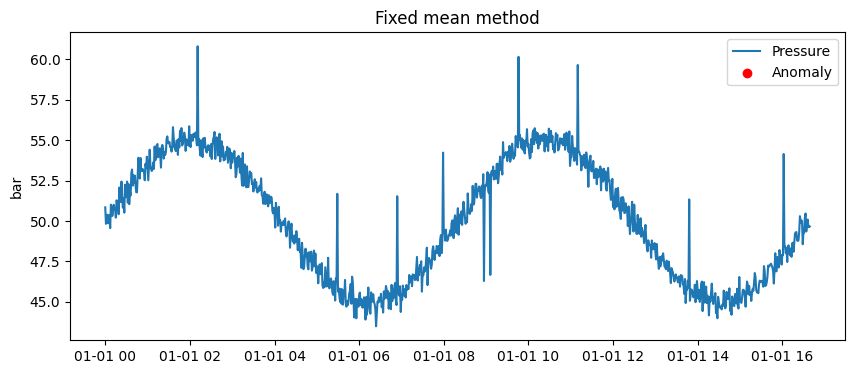

In [2]:
mean = df["pressure"].mean()
std = df["pressure"].std()
df["anomaly_fixed"] = (df["pressure"] - mean).abs() > 3 * std

print("Anomalies found (fixed mean):", df["anomaly_fixed"].sum())

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["pressure"], label="Pressure")
plt.scatter(df[df["anomaly_fixed"]]["time"], df[df["anomaly_fixed"]]["pressure"],
            color="red", label="Anomaly", zorder=3)
plt.title("Fixed mean method")
plt.ylabel("bar")
plt.legend()
plt.show()

Anomalies found (rolling): 10


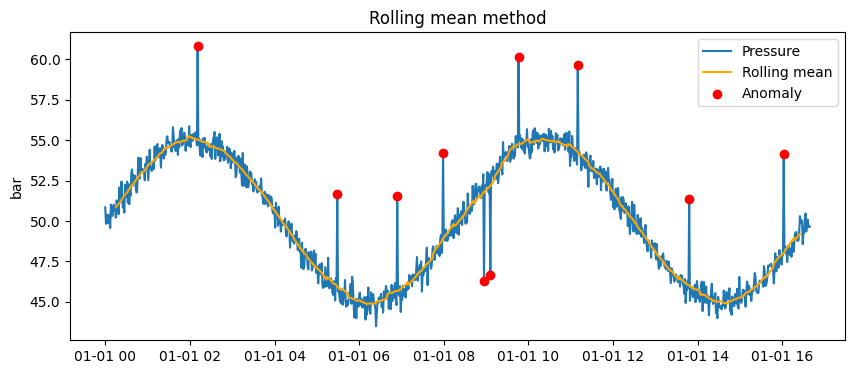

In [3]:
window = 30
roll_mean = df["pressure"].rolling(window, center=True).mean()
roll_std = df["pressure"].rolling(window, center=True).std()

df["anomaly_roll"] = (df["pressure"] - roll_mean).abs() > 3 * roll_std

print("Anomalies found (rolling):", df["anomaly_roll"].sum())

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["pressure"], label="Pressure")
plt.plot(df["time"], roll_mean, color="orange", label="Rolling mean")
plt.scatter(df[df["anomaly_roll"]]["time"], df[df["anomaly_roll"]]["pressure"],
            color="red", label="Anomaly", zorder=3)
plt.title("Rolling mean method")
plt.ylabel("bar")
plt.legend()
plt.show()